Saving library_literature_dataset.csv to library_literature_dataset.csv
DATASET NAME: Smart Library Analysis
Dataset Shape: (7800, 11)

Column Names:
['User_ID', 'User_Type', 'Department', 'Academic_Level', 'Research_Area', 'Preferred_Language', 'Access_Frequency', 'Borrowing_Frequency', 'Avg_Reading_Time_Min', 'Device_Type', 'Recommendation_Status']

Missing Values:
User_ID                  0
User_Type                0
Department               0
Academic_Level           0
Research_Area            0
Preferred_Language       0
Access_Frequency         0
Borrowing_Frequency      0
Avg_Reading_Time_Min     0
Device_Type              0
Recommendation_Status    0
dtype: int64

Duplicate Rows: 0

Numeric Statistical Summary:
       Avg_Reading_Time_Min
count               7800.00
mean                  99.57
std                   46.58
min                   20.00
25%                   59.00
50%                  100.00
75%                  140.00
max                  180.00

Categorical Column

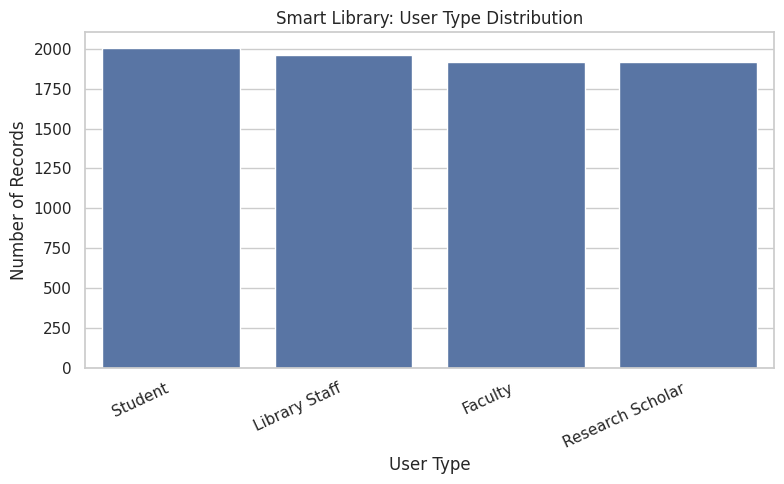

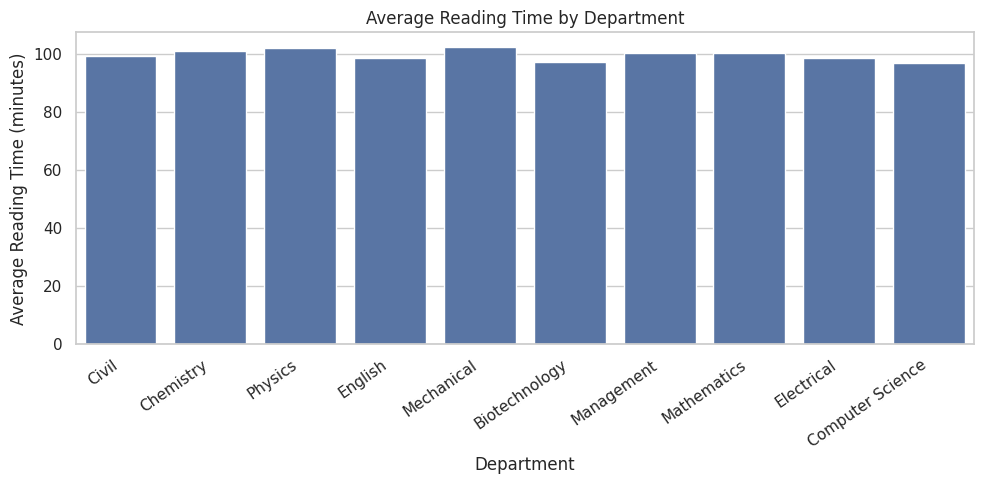

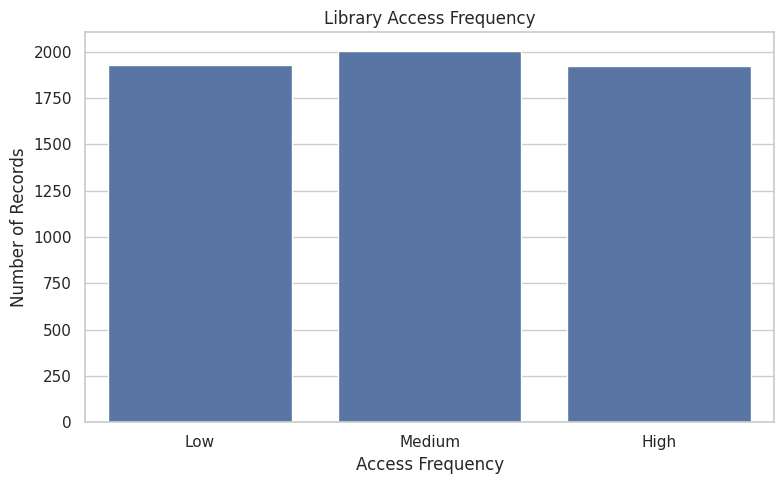

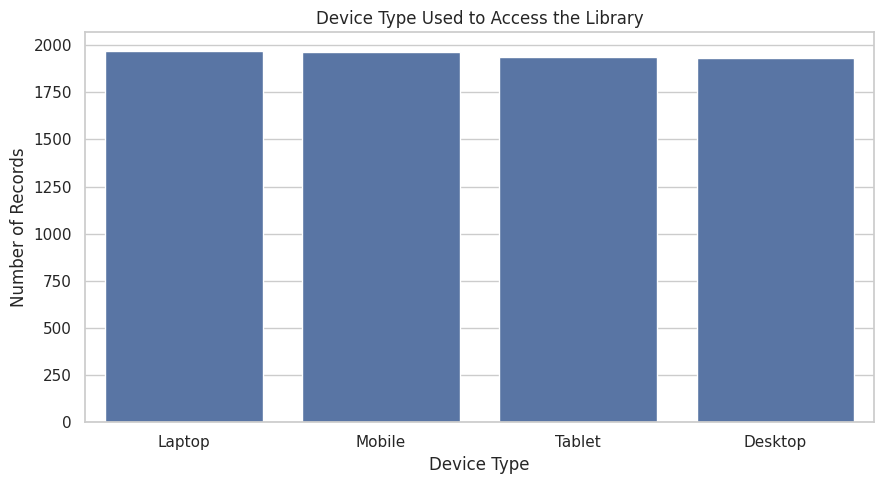

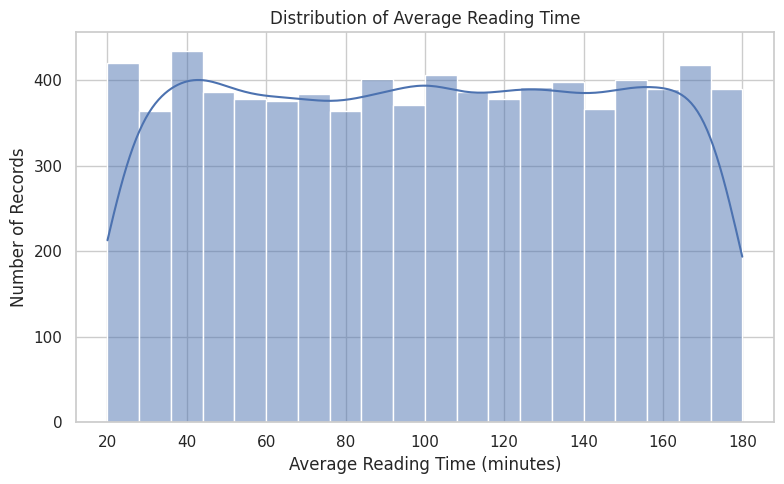


SMART LIBRARY ANALYSIS 1 COMPLETED!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load Smart Library Analysis dataset
csv_path = Path("/content/library_literature_dataset(1).csv")
if not csv_path.exists():
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded.keys())))

df = pd.read_csv(csv_path)
print("DATASET NAME: Smart Library Analysis")
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nMissing Values:")
print(df.isna().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

print("\nNumeric Statistical Summary:")
print(df.describe(include="number").round(2))

categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nCategorical Column Summaries:")
for col in categorical_cols:
    print(f"\n{col} distribution:")
    print(df[col].value_counts(dropna=False))

print("\nAverage Reading Time by User Type:")
print(df.groupby("User_Type")["Avg_Reading_Time_Min"].agg(["count", "mean", "median"]).round(2))

print("\nAverage Reading Time by Department:")
print(df.groupby("Department")["Avg_Reading_Time_Min"].mean().sort_values(ascending=False).round(2))

print("\nAccess Frequency by User Type:")
print(pd.crosstab(df["User_Type"], df["Access_Frequency"]))

print("\nBorrowing Frequency by User Type:")
print(pd.crosstab(df["User_Type"], df["Borrowing_Frequency"]))

print("\nResearch Area Distribution:")
print(df["Research_Area"].value_counts())

print("\nPreferred Language Distribution:")
print(df["Preferred_Language"].value_counts())

print("\nDevice Type Distribution:")
print(df["Device_Type"].value_counts())

print("\nRecommendation Status Distribution:")
print(df["Recommendation_Status"].value_counts())

print("\nRecommendation Status by User Type (% within user type):")
print((pd.crosstab(df["User_Type"], df["Recommendation_Status"], normalize="index") * 100).round(2))

print("\nNumeric Correlation Matrix:")
numeric_df = df.select_dtypes(include=np.number)
if not numeric_df.empty and numeric_df.shape[1] > 1:
    print(numeric_df.corr().round(3))

# Charts
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="User_Type", order=df["User_Type"].value_counts().index)
plt.title("Smart Library: User Type Distribution")
plt.xlabel("User Type"); plt.ylabel("Number of Records")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Department", y="Avg_Reading_Time_Min", estimator="mean", errorbar=None)
plt.title("Average Reading Time by Department")
plt.xlabel("Department"); plt.ylabel("Average Reading Time (minutes)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Access_Frequency", order=["Low", "Medium", "High"])
plt.title("Library Access Frequency")
plt.xlabel("Access Frequency"); plt.ylabel("Number of Records")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Device_Type", order=df["Device_Type"].value_counts().index)
plt.title("Device Type Used to Access the Library")
plt.xlabel("Device Type"); plt.ylabel("Number of Records")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["Avg_Reading_Time_Min"].dropna(), bins=20, kde=True)
plt.title("Distribution of Average Reading Time")
plt.xlabel("Average Reading Time (minutes)"); plt.ylabel("Number of Records")
plt.tight_layout(); plt.show()

print("\nSMART LIBRARY ANALYSIS 1 COMPLETED!")


Saving library_literature_dataset.csv to library_literature_dataset (1).csv
DATASET NAME: Smart Library Analysis
DATASET SHAPE: (7800, 11)

Q1. User type counts and percentages
User_Type
Student             2004
Library Staff       1961
Faculty             1920
Research Scholar    1915
Name: count, dtype: int64
User_Type
Student             25.69
Library Staff       25.14
Faculty             24.62
Research Scholar    24.55
Name: proportion, dtype: float64

Q2. Records by department
Department
English             843
Chemistry           815
Physics             793
Computer Science    784
Management          778
Mechanical          775
Civil               765
Electrical          757
Mathematics         751
Biotechnology       739
Name: count, dtype: int64

Q3. Average reading time by user type
                   mean  median  count
User_Type                             
Faculty           99.28    99.0   1920
Library Staff     99.75   100.0   1961
Research Scholar  99.90   101.0   1915
St

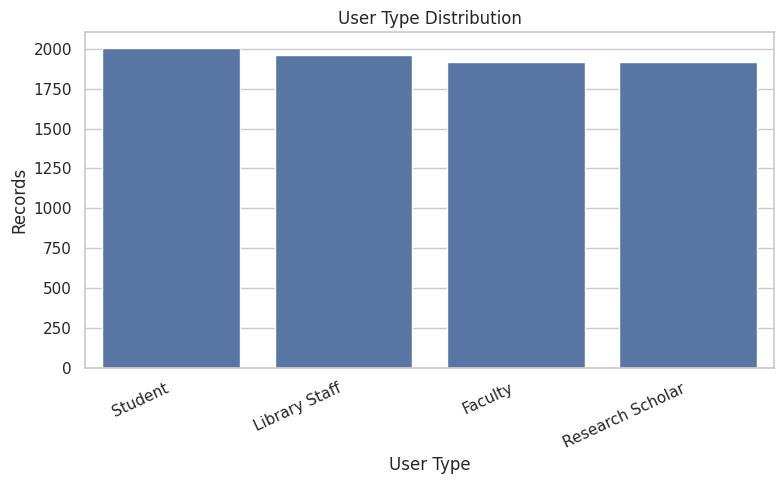

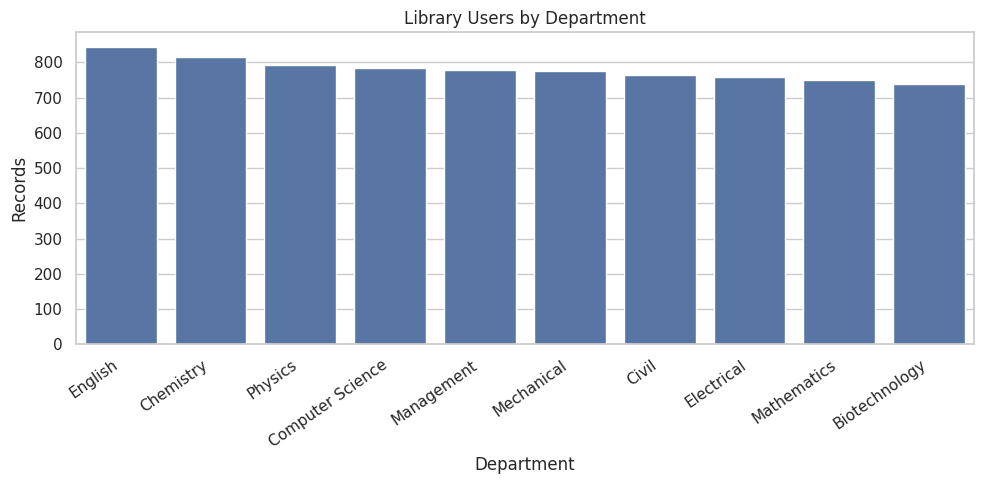

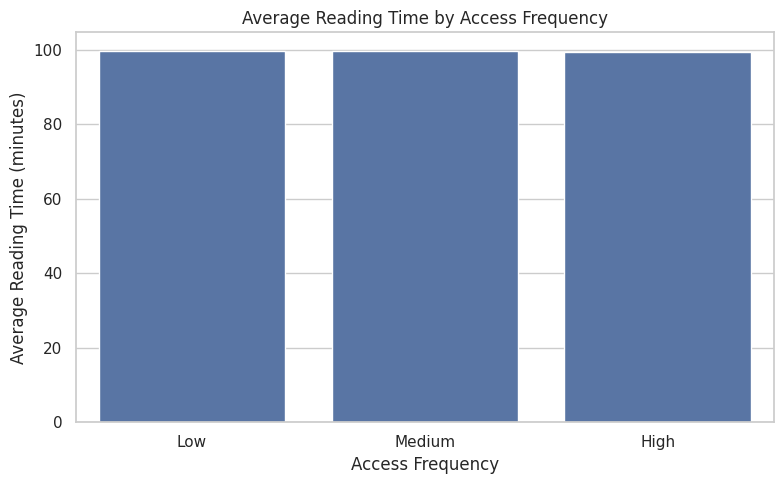

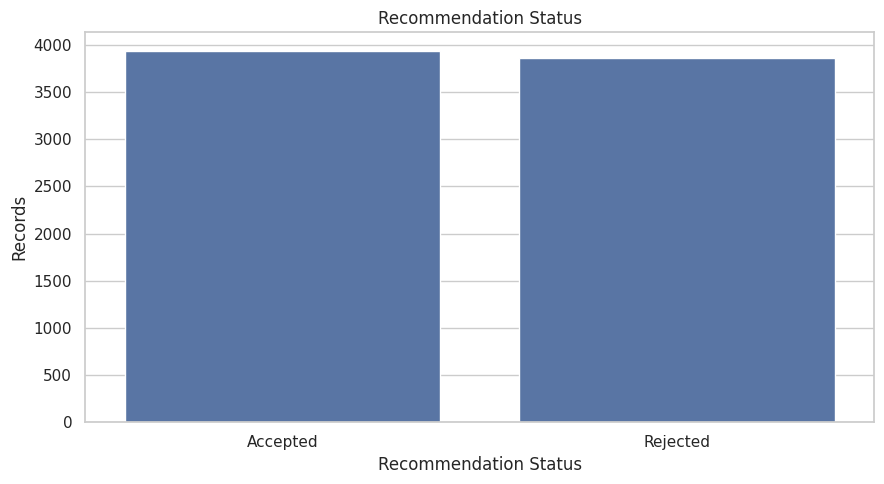


SMART LIBRARY ANALYSIS 2 COMPLETED!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load Smart Library Analysis dataset
csv_path = Path("/content/library_literature_dataset(1).csv")
if not csv_path.exists():
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded.keys())))

df = pd.read_csv(csv_path)
print("DATASET NAME: Smart Library Analysis")
print("DATASET SHAPE:", df.shape)

# Q1. What types of users use the library?
print("\nQ1. User type counts and percentages")
print(df["User_Type"].value_counts())
print((df["User_Type"].value_counts(normalize=True) * 100).round(2))

# Q2. Which departments have the most records?
print("\nQ2. Records by department")
print(df["Department"].value_counts())

# Q3. What is the average reading time for each user type?
print("\nQ3. Average reading time by user type")
print(df.groupby("User_Type")["Avg_Reading_Time_Min"].agg(["mean", "median", "count"]).round(2))

# Q4. Which departments have the highest average reading time?
print("\nQ4. Average reading time by department (highest first)")
print(df.groupby("Department")["Avg_Reading_Time_Min"].mean().sort_values(ascending=False).round(2))

# Q5. What is the most common access frequency?
print("\nQ5. Access frequency counts and percentages")
print(df["Access_Frequency"].value_counts())
print((df["Access_Frequency"].value_counts(normalize=True) * 100).round(2))

# Q6. How does access frequency differ by user type?
print("\nQ6. Access frequency by user type")
print(pd.crosstab(df["User_Type"], df["Access_Frequency"]))

# Q7. What is the most common borrowing frequency?
print("\nQ7. Borrowing frequency distribution")
print(df["Borrowing_Frequency"].value_counts())

# Q8. How does borrowing frequency differ by user type?
print("\nQ8. Borrowing frequency by user type")
print(pd.crosstab(df["User_Type"], df["Borrowing_Frequency"]))

# Q9. Which research areas are most common?
print("\nQ9. Top research areas")
print(df["Research_Area"].value_counts().head(10))

# Q10. Which preferred languages are most common?
print("\nQ10. Preferred language distribution")
print(df["Preferred_Language"].value_counts())

# Q11. Which devices are used most often?
print("\nQ11. Device type distribution")
print(df["Device_Type"].value_counts())

# Q12. What percentage of recommendations are accepted?
print("\nQ12. Recommendation status counts and percentages")
print(df["Recommendation_Status"].value_counts())
print((df["Recommendation_Status"].value_counts(normalize=True) * 100).round(2))

# Q13. Does recommendation status differ by user type?
print("\nQ13. Recommendation status by user type (% within user type)")
print((pd.crosstab(df["User_Type"], df["Recommendation_Status"], normalize="index") * 100).round(2))

# Q14. Is average reading time different by access frequency?
print("\nQ14. Average reading time by access frequency")
print(df.groupby("Access_Frequency")["Avg_Reading_Time_Min"].agg(["mean", "median", "count"]).round(2))

# Q15. Which department and research-area combinations have the most records?
print("\nQ15. Top 10 department and research-area combinations")
print(df.groupby(["Department", "Research_Area"]).size().sort_values(ascending=False).head(10))

# Q16. Numeric correlation (numeric columns only)
print("\nQ16. Numeric correlation matrix")
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] > 1:
    print(numeric_df.corr().round(3))
else:
    print("Not enough numeric columns for correlation analysis.")

# Visual summaries
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="User_Type", order=df["User_Type"].value_counts().index)
plt.title("User Type Distribution")
plt.xlabel("User Type"); plt.ylabel("Records")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Department", order=df["Department"].value_counts().index)
plt.title("Library Users by Department")
plt.xlabel("Department"); plt.ylabel("Records")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Access_Frequency", y="Avg_Reading_Time_Min",
            order=["Low", "Medium", "High"], estimator="mean", errorbar=None)
plt.title("Average Reading Time by Access Frequency")
plt.xlabel("Access Frequency"); plt.ylabel("Average Reading Time (minutes)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Recommendation_Status",
              order=df["Recommendation_Status"].value_counts().index)
plt.title("Recommendation Status")
plt.xlabel("Recommendation Status"); plt.ylabel("Records")
plt.tight_layout(); plt.show()

print("\nSMART LIBRARY ANALYSIS 2 COMPLETED!")
